# Where did it hit? Predicting an asteroid impact from its discovery astrometry

**The question.** Only a handful of asteroids have been discovered in space *before* they struck
the Earth. For each of them the only information anyone had was a few hours of telescope
positions, and from those alone astronomers predicted when and where the object would enter the
atmosphere. Then the fireball was seen, and in all three cases below meteorites were found on the
ground. *Starting from the same astrometry, can we predict the time and place of atmospheric
entry, and how early in the discovery arc was the location known?*

The three test cases:

| Object | Discovered | Entry | Where |
|---|---|---|---|
| **2008 TC3** | 2008 Oct 6, 06:39 UTC, Mt. Lemmon Survey | 2008 Oct 7, ~02:46 UTC | Nubian Desert, northern Sudan (the Almahata Sitta meteorites) |
| **2024 BX1** | 2024 Jan 20, 21:48 UTC, Piszkéstető (Hungary) | 2024 Jan 21, ~00:32 UTC | west of Berlin, Germany (meteorites found near Ribbeck) |
| **2023 CX1** | 2023 Feb 12, 20:18 UTC, Piszkéstető | 2023 Feb 13, ~02:59 UTC | over the English Channel / Normandy coast, France (meteorites found in Normandy) |

Every observation of these objects was made before impact, so "all the data" is itself a
pre-impact prediction. We also cut each arc at a few hours after discovery to replay what an
orbit computer could have said at the time.

What PyRoOrb provides along the way:

* `fetch_observations` / `Observations.select` / `fit_orbit`: the orbit from the raw MPC astrometry,
  and from any early part of it;
* `propagate` and `body_states("earth")`: the asteroid's position relative to the Earth's centre,
  second by second, in the force model of the fit (DE440 planets and Moon, relativity);
* `sample_orbits`: a cloud of orbit clones drawn from the fit's covariance, which becomes a cloud of
  entry points on the map;
* `close_approaches`: the nominal miss distance from the Earth's centre (less than an Earth radius
  means an impact).

Turning a geocentric position into latitude, longitude and altitude needs the Earth's rotation
and shape; for that we use astropy's ITRS frame and the WGS84 ellipsoid. Every key number is
checked against JPL: the **Horizons** trajectory of each impactor (JPL's independent orbit, pushed
through exactly the same Earth-fixed conversion) and, for 2008 TC3, the **CNEOS fireball
database**, which records the fireball as seen by US government sensors.

In [1]:
import json, time, urllib.parse, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import GCRS, ITRS, CartesianRepresentation, EarthLocation
from astropy.utils import iers
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
iers.conf.auto_download = False   # Earth-orientation data for 2008-2024 ships with astropy
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


## 1. From a fitted orbit to a point on the ground

PyRoOrb's `propagate` returns **heliocentric** states in ICRF axes (au, au/day), and
`body_states("earth")` the Earth's centre from the same DE440 ephemeris. Their difference is the
asteroid's geocentric position in the GCRS (geocentric, ICRF-aligned axes). Rotating that into the
Earth-fixed ITRS frame (precession, nutation, Earth rotation angle with UT1, polar motion) is one
astropy transform, and `EarthLocation.to_geodetic("WGS84")` turns it into longitude, latitude and
height above the ellipsoid.

Time scales matter at the level of seconds here: a bare number or ISO string passed to PyRoOrb is
**UTC**, and the integration runs in TDB internally (the two differ by 65-69 s for these dates).
We always pass astropy `Time` objects in UTC, so there is no ambiguity.

The **entry point** is where the trajectory first crosses **100 km** altitude, the conventional top
of the atmosphere. Above it the asteroid is ballistic to high accuracy; below it, air drag and
ablation take over and a pure orbit no longer describes the motion. We still draw the ballistic
ground track down to 30 km, ignoring drag, to show where the fireball happened; real meteorites
fall short of where a drag-free extension of that line would reach the ground.

In [2]:
AU_KM = 149_597_870.7


def earth_fixed(helio, t):
    # helio: (n_t, m, 6) heliocentric ICRF states at UTC times t (n_t,)
    # -> Earth-fixed position (n_t, m, 3) km and WGS84 lon, lat [deg], height [km]
    geo = (helio[..., :3] - pyroorb.body_states("earth", t)[:, None, :3]) * AU_KM
    rot = []                                 # GCRS -> ITRS rotation at each time, one per axis
    for e in np.eye(3):
        rep = CartesianRepresentation(np.repeat(e[:, None], len(t), axis=1) * u.km)
        rot.append(GCRS(rep, obstime=t).transform_to(ITRS(obstime=t)).cartesian.xyz.value.T)
    x = np.einsum("nij,nmj->nmi", np.stack(rot, axis=-1), geo)
    lon, lat, h = EarthLocation.from_geocentric(*np.moveaxis(x, -1, 0), unit=u.km).to_geodetic("WGS84")
    return x, lon.deg, lat.deg, h.to_value(u.km)


def crossing(t, lon, lat, h, level=100.0):
    # (m, 3): UTC JD, lon, lat where each member first drops through `level` km (NaN if never)
    out = np.full((h.shape[1], 3), np.nan)
    for j in range(h.shape[1]):
        i = np.nonzero((h[:-1, j] >= level) & (h[1:, j] < level))[0]
        if len(i):
            i = i[0]
            f = (h[i, j] - level) / (h[i, j] - h[i + 1, j])
            dlon = (lon[i + 1, j] - lon[i, j] + 180) % 360 - 180
            out[j] = (t.jd[i] + f * (t.jd[i + 1] - t.jd[i]), lon[i, j] + f * dlon,
                      lat[i, j] + f * (lat[i + 1, j] - lat[i, j]))
    return out


def entry_cloud(fit, n=500, level=100.0):
    # Entry points of n covariance clones. The time window is centred on the nominal closest
    # approach and spans +-10 sigma of its time (at least +-15 min, at most +-12 h).
    ca = pyroorb.close_approaches(fit, fit.epoch_jd() - 1, fit.epoch_jd() + 3,
                                  max_distance=0.01)[0]
    W = float(np.clip(10 * ca["sigma_time_days"] * 86400, 900, 12 * 3600))
    step = max(1.0, W / 1500)
    t = Time(ca["jd_utc"], format="jd", scale="utc") + np.arange(-W, W, step) * u.s
    ens = pyroorb.sample_orbits(fit, n=n)
    _, lon, lat, h = earth_fixed(ens.propagate(t), t)
    pts = crossing(t, lon, lat, h, level)
    miss = np.isnan(pts[:, 0]) & (h.min(axis=0) > level)    # never reached `level` in the window
    unresolved = np.isnan(pts[:, 0]) & ~miss                 # began inside the atmosphere: window too short
    return {"pts": pts, "hit": 1 - miss.mean() - unresolved.mean(), "unresolved": unresolved.mean(),
            "ca": ca, "step": step}


def horizons_geocentric(des, start, stop, n_steps):
    # JPL Horizons geometric geocentric vectors, ICRF axes, km; times UTC
    q = urllib.parse.urlencode({"format": "json", "COMMAND": f"'DES={des};'",
                                "EPHEM_TYPE": "VECTORS", "CENTER": "'500@399'",
                                "START_TIME": f"'{start}'", "STOP_TIME": f"'{stop}'",
                                "STEP_SIZE": f"'{n_steps}'", "TIME_TYPE": "UT",
                                "OUT_UNITS": "KM-S", "VEC_TABLE": "2", "CSV_FORMAT": "YES",
                                "REF_PLANE": "FRAME"})
    res = json.load(urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?" + q,
                                           timeout=60))["result"]
    solution = res.split("Target body name:")[1].split("\n")[0].split("{source:")[1].strip(" }")
    rows = [r.split(",") for r in res.split("$$SOE")[1].split("$$EOE")[0].strip().splitlines()]
    a = np.array([[float(r[0])] + [float(x) for x in r[2:8]] for r in rows])
    return Time(a[:, 0], format="jd", scale="utc"), a[:, 1:4], solution

## 2. 2008 TC3: all the astrometry

2008 TC3 was a ~4 m asteroid found by Richard Kowalski at the Mt. Lemmon Survey about 20 hours
before impact. It was the first asteroid ever discovered before it hit the Earth, and observatories
worldwide reported some 900 positions before it entered the Earth's shadow. The MPC still has
them all.

In [3]:
def load_and_fit(des):
    obs = pyroorb.fetch_observations(des)
    with warnings.catch_warnings():                    # see section 4 on this warning
        warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)
        fit = pyroorb.fit_orbit(obs, designation=des)
    return obs, fit

t0 = time.time()
obs_tc3, fit_tc3 = load_and_fit("2008 TC3")
jd = [o["jd_utc"] for o in obs_tc3]
disc = next(o for o in obs_tc3 if o.get("discovery"))
print(f"{len(obs_tc3)} observations from {len({o['obscode'] for o in obs_tc3})} stations, "
      f"{Time(min(jd), format='jd').iso[:16]} to {Time(max(jd), format='jd').iso[:16]} UTC; "
      f"discovery observation from station {disc['obscode']}")
print(f"fit: {fit_tc3.n_observations()} used, rms {fit_tc3.rms_residual():.2f}\", "
      f"force model {fit_tc3.force_model}  ({time.time() - t0:.0f} s)")
ca = pyroorb.close_approaches(fit_tc3, "2008-10-06", "2008-10-08", max_distance=0.01)[0]
print(f"nominal closest approach to the Earth's centre: {ca['distance_au'] * AU_KM:.0f} km "
      f"+- {ca['sigma_distance_au'] * AU_KM:.1f} km at {ca['date_iso']} UTC "
      "(Earth's radius is 6357-6378 km: an impact)")

883 observations from 29 stations, 2008-10-06 06:39 to 2008-10-07 01:45 UTC; discovery observation from station G96
fit: 765 used, rms 0.75", force model ASSIST(DE440+GR)  (10 s)
nominal closest approach to the Earth's centre: 5848 km +- 0.3 km at 2008-10-07 02:49:59 UTC (Earth's radius is 6357-6378 km: an impact)


The nominal trajectory passes ~5850 km from the Earth's centre, about 500 km *inside* the
surface, with a 1σ of well under a kilometre. Now the geography: the nominal trajectory second by
second from 10 minutes before to just after entry, converted to longitude, latitude and height.

In [4]:
def ecef_km(lon, lat, h_km):
    # Earth-fixed position (km) of a WGS84 longitude, latitude [deg] and height [km]
    return np.array([c.to_value(u.km) for c in
                     EarthLocation.from_geodetic(lon, lat, h_km * u.km).to_geocentric()])

def ground_track(fit, centre, before=600, after=60):
    t = Time(centre, scale="utc") + np.arange(-before, after, 0.5) * u.s
    x, lon, lat, h = earth_fixed(pyroorb.propagate(fit, t)[:, None, :], t)
    return t, x[:, 0], lon[:, 0], lat[:, 0], h[:, 0]

def at_height(trk, level):
    t, x, lon, lat, h = trk
    jd, lo, la = crossing(t, lon[:, None], lat[:, None], h[:, None], level)[0]
    return Time(jd, format="jd", scale="utc"), lo, la

trk_tc3 = ground_track(fit_tc3, "2008-10-07 02:46")
for level in (100, 50, 38.9, 30):
    tt, lo, la = at_height(trk_tc3, level)
    print(f"{level:5.1f} km  {tt.iso} UTC   lat {la:8.4f}  lon {lo:8.4f}")
t, x, lon, lat, h = trk_tc3
i = np.argmin(abs(h - 100))
v_ecef = (x[i + 1] - x[i - 1]) / ((t.jd[i + 1] - t.jd[i - 1]) * 86400)
local_up = x[i] / np.linalg.norm(x[i])
print(f"speed relative to the rotating Earth at 100 km: {np.linalg.norm(v_ecef):.2f} km/s, "
      f"entry angle {np.degrees(np.arcsin(-v_ecef @ local_up / np.linalg.norm(v_ecef))):.1f} deg "
      "below the local horizontal")

100.0 km  2008-10-07 02:45:30.139 UTC   lat  21.0886  lon  30.5345
 50.0 km  2008-10-07 02:45:41.687 UTC   lat  20.8531  lon  31.7851
 38.9 km  2008-10-07 02:45:44.307 UTC   lat  20.7979  lon  32.0710
 30.0 km  2008-10-07 02:45:46.423 UTC   lat  20.7527  lon  32.3025
speed relative to the rotating Earth at 100 km: 12.38 km/s, entry angle 20.8 deg below the local horizontal


### Checked against JPL Horizons

Horizons has its own trajectory for 2008 TC3 from JPL's orbit solution. We fetch its geocentric
vectors and push them through *the same* `earth_fixed` conversion, so any difference is a
difference in the orbits, not in the geodesy.

In [5]:
def compare_with_horizons(des, fit, start, stop):
    t, geo_jpl, solution = horizons_geocentric(des, start, stop, 600)       # 1-s steps
    geo_us = (pyroorb.propagate(fit, t)[:, :3] - pyroorb.body_states("earth", t)[:, :3]) * AU_KM
    _, lon, lat, h = earth_fixed(geo_jpl[:, None, :] / AU_KM
                                 + pyroorb.body_states("earth", t)[:, None, :3], t)
    above = h[:, 0] > 0
    d = np.linalg.norm(geo_us - geo_jpl, axis=1)[above]
    print(f"{des}: JPL solution {solution}; |PyRoOrb - Horizons| = {d.min():.2f}-{d.max():.2f} km "
          "along the final 10 minutes")
    rows = {}
    for level in (100, 38.9):
        jd, lo, la = crossing(t, lon, lat, h, level)[0]
        rows[level] = (Time(jd, format="jd", scale="utc"), lo, la)
    return rows, t, geo_jpl

hz_tc3, t_hz, geo_hz = compare_with_horizons("2008 TC3", fit_tc3, "2008-10-07 02:40", "2008-10-07 02:50")

def report(trk, hz):
    for level, (tj, lo_j, la_j) in hz.items():
        tu, lo_u, la_u = at_height(trk, level)
        dkm = np.linalg.norm(ecef_km(lo_u, la_u, level) - ecef_km(lo_j, la_j, level))
        print(f"  {level:5.1f} km:  PyRoOrb {tu.iso[11:]}  {la_u:8.4f} {lo_u:8.4f}   "
              f"Horizons {tj.iso[11:]}  {la_j:8.4f} {lo_j:8.4f}   "
              f"dt = {(tu - tj).sec:+.2f} s, {dkm:.2f} km apart")

report(trk_tc3, hz_tc3)

2008 TC3: JPL solution JPL#18; |PyRoOrb - Horizons| = 1.70-1.97 km along the final 10 minutes
  100.0 km:  PyRoOrb 02:45:30.139   21.0886  30.5345   Horizons 02:45:30.344   21.0865  30.5403   dt = -0.21 s, 0.65 km apart
   38.9 km:  PyRoOrb 02:45:44.307   20.7979  32.0710   Horizons 02:45:44.515   20.7957  32.0771   dt = -0.21 s, 0.69 km apart


### Checked against the CNEOS fireball record

The CNEOS fireball database lists the fireball's **peak-brightness** point as reported by US
government sensors: time, latitude/longitude (to 0.1°), altitude, and the pre-entry velocity
vector in the Earth-fixed frame. We compare it with our ballistic trajectory at the *same*
altitude.

In [6]:
try:
    url = ("https://ssd-api.jpl.nasa.gov/fireball.api?date-min=2008-10-07&date-max=2008-10-08"
           "&vel-comp=true")
    fb = json.load(urllib.request.urlopen(url, timeout=30))
    cneos = dict(zip(fb["fields"], fb["data"][0]))
except Exception as ex:                       # the record as it stood when this was written
    print("CNEOS fireball API unavailable:", ex)
    cneos = {"date": "2008-10-07 02:45:45", "lat": "20.9", "lat-dir": "N", "lon": "31.4",
             "lon-dir": "E", "alt": "38.9", "vel": "13.3", "vx": "-9.0", "vy": "9.0", "vz": "3.8"}
print("CNEOS:", cneos)
lat_c = float(cneos["lat"]) * (1 if cneos["lat-dir"] == "N" else -1)
lon_c = float(cneos["lon"]) * (1 if cneos["lon-dir"] == "E" else -1)
alt_c = float(cneos["alt"])

tu, lo_u, la_u = at_height(trk_tc3, alt_c)
p_us, p_cn = ecef_km(lo_u, la_u, alt_c), ecef_km(lon_c, lat_c, alt_c)
along = v_ecef / np.linalg.norm(v_ecef)
print(f"\nat {alt_c} km:  PyRoOrb {tu.iso[11:19]} UTC, {la_u:.2f} N {lo_u:.2f} E   "
      f"CNEOS {cneos['date'][11:]} UTC, {lat_c} N {lon_c} E")
print(f"  time difference {(tu - Time(cneos['date'], scale='utc')).sec:+.1f} s;  "
      f"position difference {np.linalg.norm(p_us - p_cn):.0f} km, of which "
      f"{(p_cn - p_us) @ along:+.0f} km along the flight direction")
# where along OUR track the CNEOS longitude/latitude lies
t, x, lon, lat, h = trk_tc3
k = np.argmin(np.linalg.norm(x - p_cn * (np.linalg.norm(x, axis=1)[:, None] / np.linalg.norm(p_cn)),
                             axis=1))
print(f"  our track passes over the CNEOS point at {t[k].iso[11:19]} UTC, {h[k]:.0f} km up")

v_cn = np.array([float(cneos[k]) for k in ("vx", "vy", "vz")])
print(f"\nvelocity (Earth-fixed, km/s):  PyRoOrb {np.round(v_ecef, 2)}  |v| = {np.linalg.norm(v_ecef):.2f}"
      f"\n                               CNEOS   {v_cn}  |v| = {float(cneos['vel'])}")
ang = np.degrees(np.arccos(v_ecef @ v_cn / np.linalg.norm(v_ecef) / np.linalg.norm(v_cn)))
v_flip = v_cn * [1, 1, -1]
ang_f = np.degrees(np.arccos(v_ecef @ v_flip / np.linalg.norm(v_ecef) / np.linalg.norm(v_flip)))
print(f"  angle between the two directions {ang:.0f} deg ({ang_f:.0f} deg if CNEOS's vz had the "
      "opposite sign)")

CNEOS: {'date': '2008-10-07 02:45:45', 'energy': '39.5', 'impact-e': '1', 'lat': '20.9', 'lat-dir': 'N', 'lon': '31.4', 'lon-dir': 'E', 'alt': '38.9', 'vel': '13.3', 'vx': '-9.0', 'vy': '9.0', 'vz': '3.8'}

at 38.9 km:  PyRoOrb 02:45:44 UTC, 20.80 N 32.07 E   CNEOS 02:45:45 UTC, 20.9 N 31.4 E
  time difference -0.7 s;  position difference 71 km, of which -67 km along the flight direction
  our track passes over the CNEOS point at 02:45:38 UTC, 66 km up

velocity (Earth-fixed, km/s):  PyRoOrb [-8.62  8.1  -3.66]  |v| = 12.38
                               CNEOS   [-9.   9.   3.8]  |v| = 13.3
  angle between the two directions 34 deg (2 deg if CNEOS's vz had the opposite sign)


**Reading the comparison.**

* **Against Horizons**, the PyRoOrb trajectory agrees to 1.7-2.0 km in 3-D position over the last
  10 minutes, almost all of it along the direction of motion: our asteroid runs 0.2 s ahead of
  JPL's. The points where the two cross 100 km and 38.9 km are 0.7 km apart on the map. Two independent orbit determinations, from
  the same public astrometry with different weighting, outlier rejection and software, land on the
  same spot in the Nubian Desert.
* **Against CNEOS**, the *time* of peak brightness at 38.9 km agrees to about one second, and the
  latitude to 0.1° (the precision of the record). The CNEOS position, however, lies some 70 km
  up-range of where both PyRoOrb and Horizons put the trajectory at that altitude: our track passes
  over the CNEOS point while still 66 km up. The CNEOS velocity vector also disagrees: its x and y
  components are close to ours, but its z component has the opposite sign (with the sign flipped
  the two directions agree within 2°) and its speed is ~0.9 km/s higher. A z velocity
  pointing *upward* is impossible for an object descending over the northern hemisphere's tropics,
  so this is the record's problem, not the orbit's. Two independent astrometric trajectories
  agreeing to a kilometre are the better reference here. The
  fireball and the meteorite recovery were analysed in detail by Jenniskens et al. (2009,
  *Nature* 458, 485), and the impact trajectory from the astrometry by Farnocchia et al. (2017,
  *Icarus* 294, 218).

## 3. What did we know then? Replaying the discovery of 2008 TC3

We cut the astrometry at 2, 4 and 8 hours after the discovery observation and fit each arc alone.
Each fit gives a cloud of 500 clones drawn from its covariance; every clone that crosses 100 km
gives one entry point. (Before two hours, the arc holds a single short tracklet and the orbit is
not determined at all: PyRoOrb's `is_determined` is False and a covariance cloud is meaningless.)

In [7]:
def replay(des, obs, hours, fit_all, impact):
    t_disc = min(o["jd_utc"] for o in obs)
    runs = {}
    for hrs in hours:
        sub = obs.select(t_disc - 0.01, t_disc + hrs / 24, radar=False)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)
            runs[f"first {hrs:g} h"] = (pyroorb.fit_orbit(sub, designation=des), sub)
    runs["all data"] = (fit_all, obs)
    print(f"{'arc':12s} {'obs':>4s} {'warning':>8s}  {'entry at 100 km, UTC (1 sigma)':>31s}"
          f"   {'latitude':>13s}  {'longitude':>14s}  {'clones hitting':>14s}")
    clouds = {}
    for label, (f, sub) in runs.items():
        cl = clouds[label] = entry_cloud(f)
        p = cl["pts"][~np.isnan(cl["pts"][:, 0])]
        warn = (impact.jd - max(o["jd_utc"] for o in sub)) * 24
        tm = Time(np.median(p[:, 0]), format="jd", scale="utc")
        note = f" ({cl['unresolved']:.0%} outside the time window)" if cl["unresolved"] else ""
        print(f"{label:12s} {len(sub):4d} {warn:6.1f} h  {tm.iso[:19]} +- {np.std(p[:, 0]) * 86400:7.1f} s"
              f"   {np.median(p[:, 2]):6.2f} +-{np.std(p[:, 2]):5.2f}  {np.median(p[:, 1]):7.2f} +-{np.std(p[:, 1]):5.2f}"
              f"  {cl['hit']:13.0%}{note}")
    return runs, clouds

impact_tc3 = hz_tc3[100][0]                 # Horizons' 100-km crossing, the reference entry time
runs_tc3, clouds_tc3 = replay("2008 TC3", obs_tc3, [2, 4, 8], fit_tc3, impact_tc3)

arc           obs  warning   entry at 100 km, UTC (1 sigma)        latitude       longitude  clones hitting


first 2 h      11   18.1 h  2008-10-07 03:19:36 +-  9792.5 s    21.18 +- 1.76    21.20 +-46.44           100%


first 4 h      15   17.7 h  2008-10-07 02:39:20 +-  5625.4 s    20.63 +- 0.66    33.41 +-25.97           100%


first 8 h      16   12.1 h  2008-10-07 02:45:41 +-   160.2 s    21.08 +- 0.03    30.58 +- 0.63           100%


all data      883    1.0 h  2008-10-07 02:45:30 +-     0.2 s    21.09 +- 0.00    30.53 +- 0.01           100%


"Warning" is the time from the last observation in the arc to the actual entry. The latitude and
longitude columns are medians with standard deviations over the clones that hit.

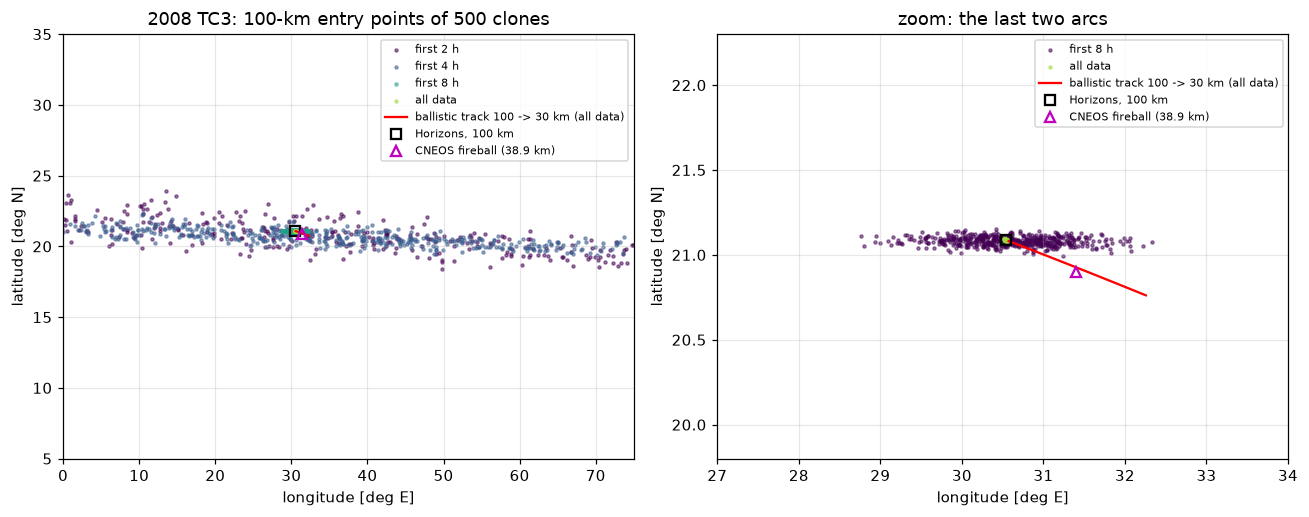

In [8]:
def entry_map(ax, clouds, trk, refs, title, zoom=None):
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(clouds)))
    for (label, cl), c in zip(clouds.items(), colors):
        p = cl["pts"]
        ax.scatter(p[:, 1], p[:, 2], s=4, color=c, alpha=0.5, label=label)
    t, x, lon, lat, h = trk
    seg = (h <= 100) & (h >= 30)
    ax.plot(lon[seg], lat[seg], "r-", lw=1.5, label="ballistic track 100 -> 30 km (all data)")
    for (lo, la, mk, lab) in refs:
        ax.plot(lo, la, mk, ms=7, mfc="none", mew=1.5, label=lab)
    if zoom:
        ax.set(xlim=zoom[0], ylim=zoom[1])
    ax.set(xlabel="longitude [deg E]", ylabel="latitude [deg N]", title=title)
    ax.legend(fontsize=7, loc="best")

tj, lo_j, la_j = hz_tc3[100]
refs = [(lo_j, la_j, "ks", "Horizons, 100 km"), (lon_c, lat_c, "m^", "CNEOS fireball (38.9 km)")]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
entry_map(axs[0], clouds_tc3, trk_tc3, refs, "2008 TC3: 100-km entry points of 500 clones",
          zoom=((0, 75), (5, 35)))
entry_map(axs[1], {k: clouds_tc3[k] for k in ("first 8 h", "all data")}, trk_tc3, refs,
          "zoom: the last two arcs", zoom=((27, 34), (19.8, 22.3)))
plt.tight_layout()
plt.show()

**Reading the replay.**

* **Two and four hours** of data (11 and 15 positions, all from the discovery night) already make
  the impact all but certain: every clone hits the Earth. They cannot say *when*: the entry time is
  uncertain by 1.5-2.7 hours, and since the Earth turns 15° per hour, the clones are smeared
  along a band of latitude near 21° N that runs a large part of the way around the globe.
  Latitude is pinned long before longitude: latitude follows from the asteroid's path in space,
  longitude from *when* it arrives.
* **Eight hours** (16 positions, 12 h before entry) shrink the timing to ±2.7 minutes and the entry
  point to ±0.6° in longitude (about ±65 km) over northern Sudan.
* **All data** (19 h of arc, ending 1 h before entry) give the entry time to ±0.2 s and the entry
  point to well under a kilometre; the nominal entry is 0.2 s and 0.7 km from Horizons'.

The early numbers are from linear covariance clouds: honest about the size of the uncertainty,
but only approximate in its shape when the arc is a few hours long (the real uncertainty region is
curved), so the fraction of clones that hit is indicative, not a formal impact probability. They
are a reconstruction from today's MPC file, not of what was on the wire at the time: positions were
remeasured and added later.

## 4. 2024 BX1 and 2023 CX1

Both were found by Krisztián Sárneczky at the Piszkéstető station of Konkoly Observatory, only
a few hours before they hit: 2024 BX1 under three hours before, 2023 CX1 under seven. The
astrometry is dense (dozens of observatories reacted within minutes of the alert), but the arcs
are very short.

In [9]:
t0 = time.time()
obs_bx1, fit_bx1 = load_and_fit("2024 BX1")
obs_cx1, fit_cx1 = load_and_fit("2023 CX1")
for des, obs, fit in (("2024 BX1", obs_bx1, fit_bx1), ("2023 CX1", obs_cx1, fit_cx1)):
    jd = [o["jd_utc"] for o in obs]
    print(f"{des}: {len(obs)} obs, arc {Time(min(jd), format='jd').iso[:16]} to "
          f"{Time(max(jd), format='jd').iso[11:16]} UTC ({(max(jd) - min(jd)) * 24:.1f} h); "
          f"fit uses {fit.n_observations()}, rms {fit.rms_residual():.2f}\"; "
          f"is_determined = {fit.is_determined}")
    r = fit.determinacy()["range"]
    print(f"    range profile: distance at the first observation {r['rho_lo'] * AU_KM:,.0f}-"
          f"{r['rho_hi'] * AU_KM:,.0f} km, best chi2/dof {r['chi2_per_dof']:.1f}; "
          f"verdict: {r['reason']}")
print(f"({time.time() - t0:.0f} s)")

2024 BX1: 327 obs, arc 2024-01-20 21:48 to 00:24 UTC (2.6 h); fit uses 279, rms 0.60"; is_determined = False
    range profile: distance at the first observation 111,543-111,652 km, best chi2/dof 0.4; verdict: the delivered orbit sits outside the distances the data support
2023 CX1: 368 obs, arc 2023-02-12 20:18 to 02:52 UTC (6.6 h); fit uses 300, rms 0.58"; is_determined = False
    range profile: distance at the first observation 226,334-226,337 km, best chi2/dof 148.8; verdict: no orbit fits this arc at any distance
(48 s)


**A false alarm from the determinacy check.** PyRoOrb flags both full fits as *not determined*.
That verdict is wrong here: the fits match hundreds of positions at 0.6" rms, and their
predictions (below) agree with JPL's. The verdict comes from the *range profile*, which refits a
thinned subset of the arc at a grid of fixed distances and asks whether a narrow interval of
distances fits. It misfires in two different ways for these objects, which are deep inside the
Earth's gravity well and moving at 15 km/s relative to it:

* **2024 BX1**: the profile pins the distance at the first observation to ±0.05 % (about
  111 600 km), but then compares it with the fitted orbit's distance taken at the orbit's *epoch*,
  1.6 hours later. For an ordinary asteroid the two hardly differ; for an object falling towards
  the Earth they differ by half. Hence "the delivered orbit sits outside the distances the data
  support".
* **2023 CX1**: the profile's best trial orbit fits the thinned 6.6-hour arc only at
  χ²/dof ≈ 150, far worse than the full fit does, so it reports that "no orbit fits this arc at
  any distance".

Both are limitations of the check, not of the orbits, so we suppress the warning and use the fits
(the same applies to some of the partial arcs below).

In [10]:
hz_bx1, *_ = compare_with_horizons("2024 BX1", fit_bx1, "2024-01-21 00:27", "2024-01-21 00:37")
trk_bx1 = ground_track(fit_bx1, "2024-01-21 00:33")
report(trk_bx1, hz_bx1)
hz_cx1, *_ = compare_with_horizons("2023 CX1", fit_cx1, "2023-02-13 02:54", "2023-02-13 03:04")
trk_cx1 = ground_track(fit_cx1, "2023-02-13 03:00")
report(trk_cx1, hz_cx1)

2024 BX1: JPL solution JPL#9; |PyRoOrb - Horizons| = 0.90-1.16 km along the final 10 minutes


  100.0 km:  PyRoOrb 00:32:37.954   52.5841  12.3559   Horizons 00:32:38.030   52.5849  12.3567   dt = -0.08 s, 0.11 km apart
   38.9 km:  PyRoOrb 00:32:42.100   52.6227  12.5769   Horizons 00:32:42.177   52.6235  12.5777   dt = -0.08 s, 0.11 km apart


2023 CX1: JPL solution JPL#14; |PyRoOrb - Horizons| = 0.91-1.19 km along the final 10 minutes


  100.0 km:  PyRoOrb 02:59:13.453   49.9193  -0.1479   Horizons 02:59:13.373   49.9190  -0.1467   dt = +0.08 s, 0.09 km apart
   38.9 km:  PyRoOrb 02:59:19.223   49.8236   0.5685   Horizons 02:59:19.143   49.8233   0.5696   dt = +0.08 s, 0.09 km apart


In [11]:
runs_bx1, clouds_bx1 = replay("2024 BX1", obs_bx1, [0.5, 1, 1.5], fit_bx1, hz_bx1[100][0])
print()
runs_cx1, clouds_cx1 = replay("2023 CX1", obs_cx1, [0.5, 1, 2, 4], fit_cx1, hz_cx1[100][0])

arc           obs  warning   entry at 100 km, UTC (1 sigma)        latitude       longitude  clones hitting


first 0.5 h     7    2.3 h  2024-01-21 00:27:26 +-  2633.6 s    51.47 +- 5.40    12.86 +- 5.27           100%


first 1 h      13    1.7 h  2024-01-21 00:32:27 +-   181.1 s    52.52 +- 0.42    12.37 +- 0.17           100%


first 1.5 h    53    1.2 h  2024-01-21 00:32:36 +-     8.3 s    52.59 +- 0.00    12.36 +- 0.02           100%


all data      327    0.1 h  2024-01-21 00:32:37 +-     0.1 s    52.58 +- 0.00    12.36 +- 0.00           100%



arc           obs  warning   entry at 100 km, UTC (1 sigma)        latitude       longitude  clones hitting


first 0.5 h     3    6.2 h  2023-02-13 01:27:17 +- 12244.7 s    46.18 +-17.72     5.42 +-37.35            92%


first 1 h      10    5.8 h  2023-02-13 03:02:16 +-  1173.0 s    49.79 +- 0.89    -0.52 +- 2.46           100%


first 2 h      25    4.7 h  2023-02-13 02:58:47 +-    29.6 s    49.97 +- 0.02    -0.02 +- 0.06           100%


first 4 h     108    2.7 h  2023-02-13 02:59:05 +-     3.5 s    49.92 +- 0.00    -0.13 +- 0.00           100%


all data      368    0.1 h  2023-02-13 02:59:13 +-     0.0 s    49.92 +- 0.00    -0.15 +- 0.00           100%


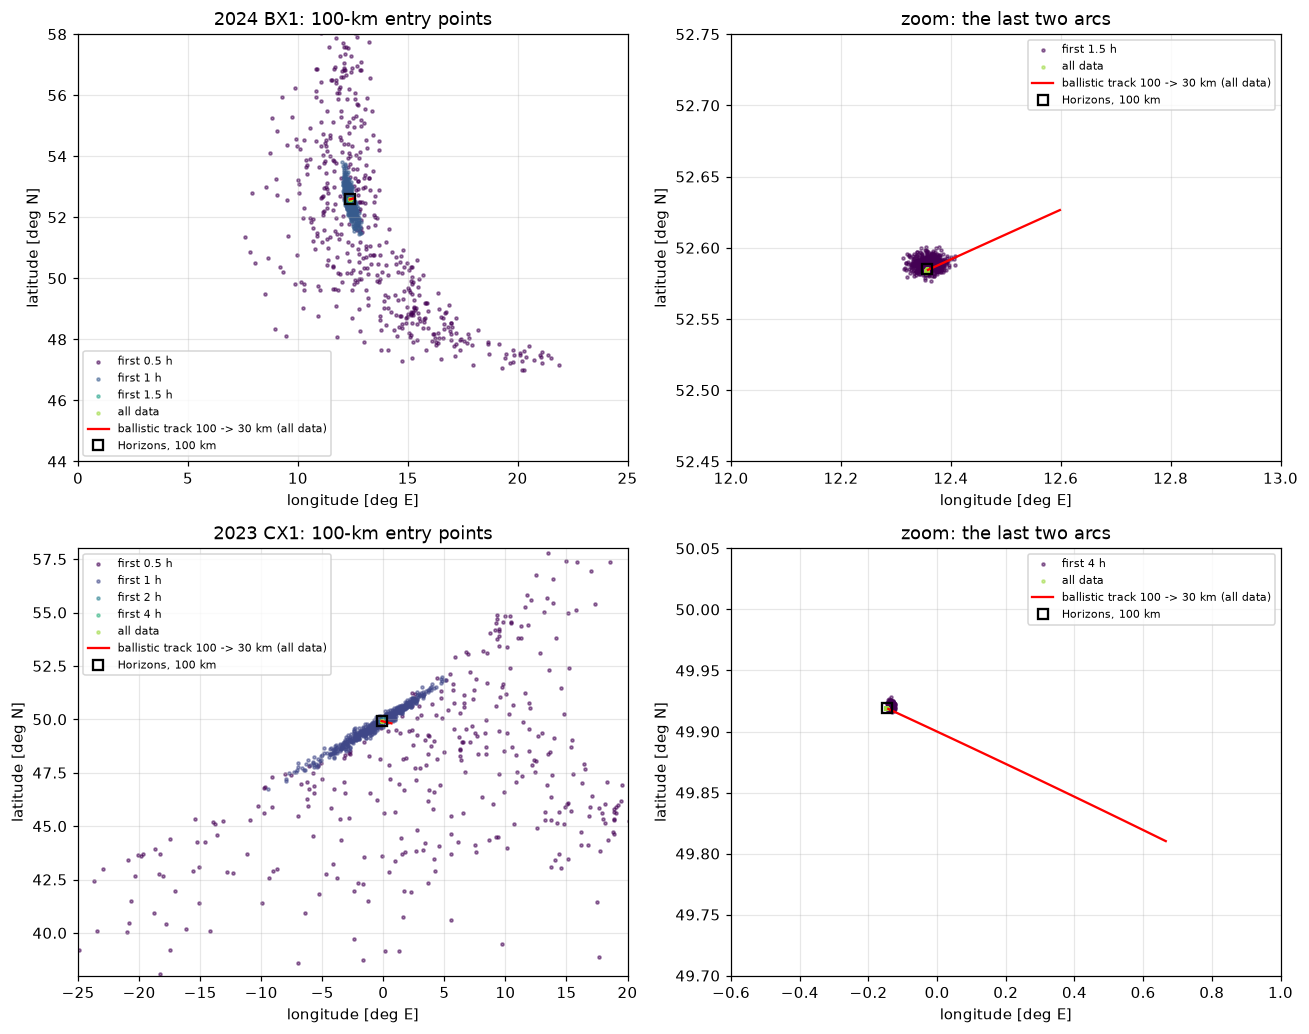

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9.5))
for row, (des, clouds, trk, hz, wide, tight) in enumerate((
        ("2024 BX1", clouds_bx1, trk_bx1, hz_bx1, ((0, 25), (44, 58)), ((12.0, 13.0), (52.45, 52.75))),
        ("2023 CX1", clouds_cx1, trk_cx1, hz_cx1, ((-25, 20), (38, 58)), ((-0.6, 1.0), (49.7, 50.05))))):
    tj, lo_j, la_j = hz[100]
    refs = [(lo_j, la_j, "ks", "Horizons, 100 km")]
    entry_map(axs[row, 0], clouds, trk, refs, f"{des}: 100-km entry points", zoom=wide)
    late = {k: clouds[k] for k in list(clouds)[-2:]}
    entry_map(axs[row, 1], late, trk, refs, "zoom: the last two arcs", zoom=tight)
plt.tight_layout()
plt.show()

**Reading the two short arcs.**

* **2024 BX1**: half an hour of data (7 positions, 2.3 h before impact) already sends every one of the
  clones into the atmosphere, over Europe, but their timing is uncertain by ±45 minutes and the
  entry point by several degrees. With **one hour** of data (13 positions, 1.7 h before impact) the
  entry is pinned to ±3 minutes and about ±45 km, west of Berlin. By 1.5 hours the time is known
  to ±8 s.
* **2023 CX1**: the first half hour (3 positions) says little: 92 % of the clones hit, anywhere
  from Spain to Scandinavia, over a span of hours. The first hour (10 positions,
  5.8 h before entry) gives a hit for every clone but a timing uncertain by ±20 minutes, smeared
  along the Channel; two hours of data pin the entry to ±30 s and ±0.06° in longitude (±4 km); four
  hours to ±3.5 s.
* In both cases the full fit and Horizons put the 100-km entry point 0.1 km apart and the entry
  time 0.08 s apart.

Short as the arcs are, these objects were so close that the parallax between observatories
hundreds of km apart measures their distance directly, which is why an hour or two suffices.

## 5. How good is a kilometre? PyRoOrb vs Horizons in units of the uncertainty

The 3-D position differences from Horizons are 1-2 km, mostly along the track. Is that within PyRoOrb's own uncertainty?
`propagate(..., covariance=True)` carries the fit's covariance to any time; we evaluate the
difference vector five minutes before entry against it.

In [13]:
print(f"{'object':9s} {'|diff| km':>9s} {'1-sigma along diff, km':>23s} {'Mahalanobis (3-D)':>18s}"
      f" {'entry-time sigma, s':>20s}")
for des, fit, hz in (("2008 TC3", fit_tc3, hz_tc3), ("2024 BX1", fit_bx1, hz_bx1),
                     ("2023 CX1", fit_cx1, hz_cx1)):
    t = hz[100][0] - 5 * u.min
    tt, geo_jpl, _ = horizons_geocentric(des, t.iso[:19], (t + 1 * u.min).iso[:19], 1)
    s, cov = pyroorb.propagate(fit, tt[:1], covariance=True)
    d = ((s[0, :3] - pyroorb.body_states("earth", tt[:1])[0, :3]) * AU_KM - geo_jpl[0])
    C = cov[0, :3, :3] * AU_KM ** 2
    sig_along = np.sqrt(d @ C @ d) / np.linalg.norm(d)
    maha = np.sqrt(d @ np.linalg.solve(C, d))
    cl = {"2008 TC3": clouds_tc3, "2024 BX1": clouds_bx1, "2023 CX1": clouds_cx1}[des]["all data"]
    print(f"{des:9s} {np.linalg.norm(d):9.2f} {sig_along:23.2f} {maha:18.1f} "
          f"{np.nanstd(cl['pts'][:, 0]) * 86400:20.2f}")

object    |diff| km  1-sigma along diff, km  Mahalanobis (3-D)  entry-time sigma, s


2008 TC3       1.72                    1.85                1.5                 0.18


2024 BX1       0.93                    0.82                3.2                 0.07


2023 CX1       0.92                    0.28                4.0                 0.02


The positional differences from JPL amount to 1.5-4 of PyRoOrb's formal sigmas (the
Mahalanobis distance accounts for the strongly elongated shape of the uncertainty ellipsoid, so
it can exceed the plain ratio of difference to 1σ). That is the usual size of the disagreement
between two independent orbit determinations from the same data: each makes its own choices of
observation weights, outlier rejection and star-catalogue debiasing, and those choices move the
solution by about its own uncertainty. At the level that matters here, both put the entry point
in the same place to within a couple of kilometres, smaller than the fireball itself is long.

## Takeaways

* **The astrometry alone predicts the entry point to under a kilometre and the entry time to a
  fraction of a second** for all three impactors. Against JPL's Horizons trajectories, pushed
  through the same Earth-fixed conversion, the 100-km entry points differ by 0.1-0.7 km and the
  entry times by 0.08-0.21 s, 1.5-4 of PyRoOrb's formal sigmas.
* **How early?** For 2008 TC3, two hours of arc (11 positions, 18 h before entry) already made
  the impact all but certain, and eight hours (12 h before entry) placed the entry over northern
  Sudan to about ±65 km and ±3 minutes. For 2024 BX1 one hour of arc
  (1.7 h before impact), and for 2023 CX1 two hours (4.7 h before), pinned it to tens of km
  or better. In each case the latitude settled before the longitude: the path in space is fixed
  first, the arrival time (and so the Earth's rotation underneath) later.
* **Against the CNEOS fireball record** for 2008 TC3, the time at 38.9 km agrees to a second and
  the latitude to its 0.1° precision, but the CNEOS longitude sits ~70 km up-range and its velocity
  vector has an impossible upward z component. The independent astrometric trajectories (ours
  and JPL's) agree with each other; satellite fireball locations are the less precise reference.
* All of this used only the public API (`fetch_observations`, `Observations.select`, `fit_orbit`,
  `propagate`, `body_states`, `close_approaches`, `sample_orbits`) plus astropy for the Earth's
  rotation and shape.

**Caveats.**

* Below ~100 km the motion is no longer ballistic. The 30-km end of the ground tracks ignores
  drag; real fragments decelerate, break up and fall short of the drag-free line, then drift with
  the wind (the "dark flight" that sets where meteorites are found). We predict where the object
  *entered*, not where its meteorites landed.
* Early-arc clouds come from the linear covariance (`sample_orbits(method="covariance")`). For
  arcs of an hour or two the true uncertainty region is curved, so the shape of those clouds and
  the fraction of clones that hit are indicative, not a formal impact probability.
* The arcs are cut from today's MPC file, which includes later remeasurements; the replay is
  representative of, not identical to, what was available at the time.
* PyRoOrb's `is_determined` flag reports the full 2024 BX1 and 2023 CX1 fits (and some partial
  arcs) as undetermined, although they fit the data well and agree with JPL; section 4 shows
  why. We ignore the flag for these objects.